# מאפיית דנה: מערכת הזמנות כגרף LangGraph

המחברת בונה מערכת הזמנות למאפייה כגרף LangGraph, לפי המפרט ב־`prompt.md`.
כל הקוד דטרמיניסטי: אין קריאות ל־LLM ואין צורך ב־API key.

מבנה המחברת: התקנה ← נתונים ← State ← Nodes ← Conditional edges ← בניית הגרף ← ציור ← הרצות ובדיקות.

In [1]:
%pip install -q langgraph

In [2]:
import operator
from typing import Annotated, Literal, Optional, TypedDict

import pandas as pd
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

## נתונים
תפריט, מלאי, שרשרת תחליפים וקבועים של משלוח והנחה. המלאי קבוע ולא משתנה בין הזמנות.

In [3]:
MENU = {"challah": 18, "babka": 45, "rugelach": 30, "sourdough": 25}
STOCK = {"challah": 10, "babka": 0, "rugelach": 3, "sourdough": 4}

# The next product to offer when one runs out. Challah has no substitute.
NEXT_SUBSTITUTE = {"babka": "rugelach", "rugelach": "sourdough",
                   "sourdough": "challah", "challah": None}
MAX_SUBSTITUTIONS = 2

HEBREW_NAMES = {"challah": "חלה", "babka": "באבקה",
                "rugelach": "קופסת רוגלך", "sourdough": "כיכר מחמצת"}

VALID_DAYS = ("Sunday", "Monday", "Tuesday", "Wednesday",
              "Thursday", "Friday", "Saturday")

DELIVERY_CITIES = {"jerusalem", "ירושלים"}
DELIVERY_FEE = 20

DISCOUNT_RATE = 0.15
DISCOUNT_THRESHOLD = 150      # discount only when subtotal > 150
NO_DISCOUNT_DAY = "Friday"

SIGNATURE = "באהבה, דנה"


def fmt(amount):
    """Show 173.0 as 173 and 157.7 as 157.7."""
    return f"{amount:g}"


def as_number(amount):
    amount = round(amount, 2)
    return int(amount) if amount == int(amount) else amount

## State
הזיכרון המשותף של הגרף. כל node מקבל את ה־state המלא ומחזיר רק את השדות שהוא משנה.

`steps` מוגדר עם reducer מסוג `operator.add`, ולכן כל node **מוסיף** את הצעד שלו לרשימה במקום לדרוס אותה.

In [4]:
class State(TypedDict, total=False):
    # input
    item: Optional[str]
    quantity: object
    day: str
    city: Optional[str]
    # work
    requested_item: str      # the product the customer asked for
    error: str               # why the input is invalid ("" if valid)
    attempts: int            # how many substitutes were tried
    in_stock: bool           # enough stock for the current item?
    city_type: str           # "jerusalem" / "empty" / "other"
    subtotal: float
    discount: float
    delivery_fee: int
    # output (item is also an output: the product actually sold)
    status: str
    delivery: str
    total: float
    message: str
    steps: Annotated[list[str], operator.add]

## Nodes
כל node הוא פונקציית Python רגילה שמבצעת צעד אחד.

In [5]:
def validate_input(state: State) -> dict:
    raw_item, quantity, raw_day = state.get("item"), state.get("quantity"), state.get("day")
    item = str(raw_item).strip().lower() if raw_item is not None else ""
    day = str(raw_day).strip().capitalize() if raw_day is not None else ""

    if item not in MENU:
        error = f"unknown product {raw_item!r}"
    elif not isinstance(quantity, int) or isinstance(quantity, bool) or quantity <= 0:
        error = f"invalid quantity {quantity!r}"
    elif day not in VALID_DAYS:
        error = f"invalid day {raw_day!r}"
    else:
        error = ""

    if error:
        return {"error": error, "steps": [f"validate_input: invalid, {error}"]}
    return {"item": item, "day": day, "requested_item": item, "attempts": 0, "error": "",
            "steps": [f"validate_input: ok, {quantity} x {item} on {day}"]}


def reject_invalid(state: State) -> dict:
    message = ("שלום, ותודה שפניתם אלינו!\n"
               "לצערי לא הצלחנו להבין את ההזמנה שהתקבלה. "
               "אפשר לנסות למלא את הטופס שוב? נשמח לאפות בשבילכם.\n"
               + SIGNATURE)
    return {"status": "rejected", "item": None, "delivery": "pickup", "total": 0,
            "message": message, "steps": ["reject_invalid: order rejected"]}


def check_stock(state: State) -> dict:
    item, quantity = state["item"], state["quantity"]
    in_stock = STOCK[item] >= quantity
    result = "enough" if in_stock else "not enough"
    return {"in_stock": in_stock,
            "steps": [f"check_stock: {STOCK[item]} {item} for {quantity}, {result}"]}


def find_substitute(state: State) -> dict:
    current, quantity = state["item"], state["quantity"]
    candidate = NEXT_SUBSTITUTE[current]
    if candidate is None:
        return {"in_stock": False, "steps": [f"find_substitute: no substitute for {current}"]}

    attempts = state["attempts"] + 1
    in_stock = STOCK[candidate] >= quantity
    result = "enough" if in_stock else f"only {STOCK[candidate]}"
    return {"item": candidate, "attempts": attempts, "in_stock": in_stock,
            "steps": [f"find_substitute: offer #{attempts} {current} -> {candidate}, {result}"]}


def cancel_order(state: State) -> dict:
    requested = HEBREW_NAMES[state["requested_item"]]
    quantity = state["quantity"]
    if state["attempts"] > 0:
        tried = "וגם המאפים שניסינו להציע במקומו לא מספיקים"
    else:
        tried = "ואין לנו מאפה חלופי להציע"
    message = (f"שלום, ותודה רבה על ההזמנה!\n"
               f"מצטערת מאוד, אין לנו היום מספיק {requested} ל־{quantity} יחידות, "
               f"{tried}. נאלצנו לבטל את ההזמנה.\n"
               f"מקווה מאוד לראות אתכם בפעם הבאה!\n" + SIGNATURE)
    return {"status": "rejected", "item": None, "delivery": "pickup", "total": 0,
            "message": message,
            "steps": [f"cancel_order: cancelled after {state['attempts']} offers"]}


def price_order(state: State) -> dict:
    item, quantity = state["item"], state["quantity"]
    subtotal = MENU[item] * quantity
    return {"subtotal": subtotal, "discount": 0,
            "steps": [f"price_order: {quantity} x {item} = {fmt(subtotal)}"]}


def apply_discount(state: State) -> dict:
    discount = round(state["subtotal"] * DISCOUNT_RATE, 2)
    return {"discount": discount,
            "steps": [f"apply_discount: 15% off {fmt(state['subtotal'])} = -{fmt(discount)}"]}


def check_city(state: State) -> dict:
    city = state.get("city")
    city = "" if city is None else str(city).strip()
    if city == "":
        city_type = "empty"
    elif city.lower() in DELIVERY_CITIES:
        city_type = "jerusalem"
    else:
        city_type = "other"
    return {"city": city, "city_type": city_type,
            "steps": [f"check_city: {city!r} -> {city_type}"]}


def delivery_jerusalem(state: State) -> dict:
    return {"delivery": "delivery", "delivery_fee": DELIVERY_FEE,
            "steps": [f"delivery_jerusalem: courier, fee {DELIVERY_FEE}"]}


def pickup(state: State) -> dict:
    return {"delivery": "pickup", "delivery_fee": 0,
            "steps": ["pickup: pickup from the shop, free"]}


def pickup_out_of_area(state: State) -> dict:
    return {"delivery": "pickup", "delivery_fee": 0,
            "steps": [f"pickup_out_of_area: no delivery to {state['city']}, switched to pickup"]}


def finalize(state: State) -> dict:
    item, requested, quantity = state["item"], state["requested_item"], state["quantity"]
    discount = state.get("discount", 0)
    total = as_number(state["subtotal"] - discount + state["delivery_fee"])

    lines = ["היי, תודה רבה על ההזמנה!"]
    if item != requested:
        lines.append(f"לא נשאר לנו היום מספיק {HEBREW_NAMES[requested]}, "
                     f"אז הכנו לכם במקום {quantity} × {HEBREW_NAMES[item]}. מקווה שתאהבו!")
    else:
        lines.append(f"הכנו לכם {quantity} × {HEBREW_NAMES[item]}.")
    if state["city_type"] == "other":
        lines.append(f"אנחנו עדיין לא מגיעים עם משלוחים ל{state['city']}, "
                     "אז העברנו את ההזמנה לאיסוף עצמי מהחנות, בלי עלות.")
    elif state["delivery"] == "delivery":
        lines.append(f"ההזמנה תגיע אליכם עם שליח בירושלים (משלוח {DELIVERY_FEE} ₪).")
    else:
        lines.append("ההזמנה תחכה לכם בחנות לאיסוף.")
    if discount:
        lines.append(f"ובגלל שזו הזמנה גדולה, קיבלתם 15% הנחה על המאפים ({fmt(discount)} ₪)!")
    lines.append(f"סה״כ לתשלום: {fmt(total)} ₪.")
    lines.append(SIGNATURE)

    return {"status": "accepted", "total": total, "message": "\n".join(lines),
            "steps": [f"finalize: accepted, total {fmt(total)}"]}

## Conditional edges
כל פונקציית ניתוב קוראת את ה־state ומחזירה את שם ה־node הבא.
`Literal` מפרט את היעדים האפשריים, כדי ש־LangGraph יוכל לצייר את הגרף.

In [6]:
def route_validation(state: State) -> Literal["reject_invalid", "check_stock"]:
    return "reject_invalid" if state["error"] else "check_stock"


def route_stock(state: State) -> Literal["price_order", "find_substitute"]:
    return "price_order" if state["in_stock"] else "find_substitute"


def route_substitute(state: State) -> Literal["price_order", "find_substitute", "cancel_order"]:
    if state["in_stock"]:
        return "price_order"
    if state["attempts"] < MAX_SUBSTITUTIONS and NEXT_SUBSTITUTE[state["item"]] is not None:
        return "find_substitute"
    return "cancel_order"


def route_discount(state: State) -> Literal["apply_discount", "check_city"]:
    if state["subtotal"] > DISCOUNT_THRESHOLD and state["day"] != NO_DISCOUNT_DAY:
        return "apply_discount"
    return "check_city"


def route_delivery(state: State) -> Literal["delivery_jerusalem", "pickup", "pickup_out_of_area"]:
    return {"jerusalem": "delivery_jerusalem",
            "empty": "pickup",
            "other": "pickup_out_of_area"}[state["city_type"]]

## בניית הגרף
`add_node` רושם כל פונקציה כ־node, `add_edge` מחבר קשתות קבועות, ו־`add_conditional_edges` מחבר קשתות מותנות.

In [7]:
builder = StateGraph(State)

for node in (validate_input, reject_invalid, check_stock, find_substitute, cancel_order,
             price_order, apply_discount, check_city,
             delivery_jerusalem, pickup, pickup_out_of_area, finalize):
    builder.add_node(node.__name__, node)

# Edges
builder.add_edge(START, "validate_input")
builder.add_edge("reject_invalid", END)
builder.add_edge("cancel_order", END)
builder.add_edge("apply_discount", "check_city")
builder.add_edge("delivery_jerusalem", "finalize")
builder.add_edge("pickup", "finalize")
builder.add_edge("pickup_out_of_area", "finalize")
builder.add_edge("finalize", END)

# Conditional edges
builder.add_conditional_edges("validate_input", route_validation)
builder.add_conditional_edges("check_stock", route_stock)
builder.add_conditional_edges("find_substitute", route_substitute)
builder.add_conditional_edges("price_order", route_discount)
builder.add_conditional_edges("check_city", route_delivery)

graph = builder.compile()

## ציור הגרף
קשתות מותנות מסומנות בקו מקווקו.

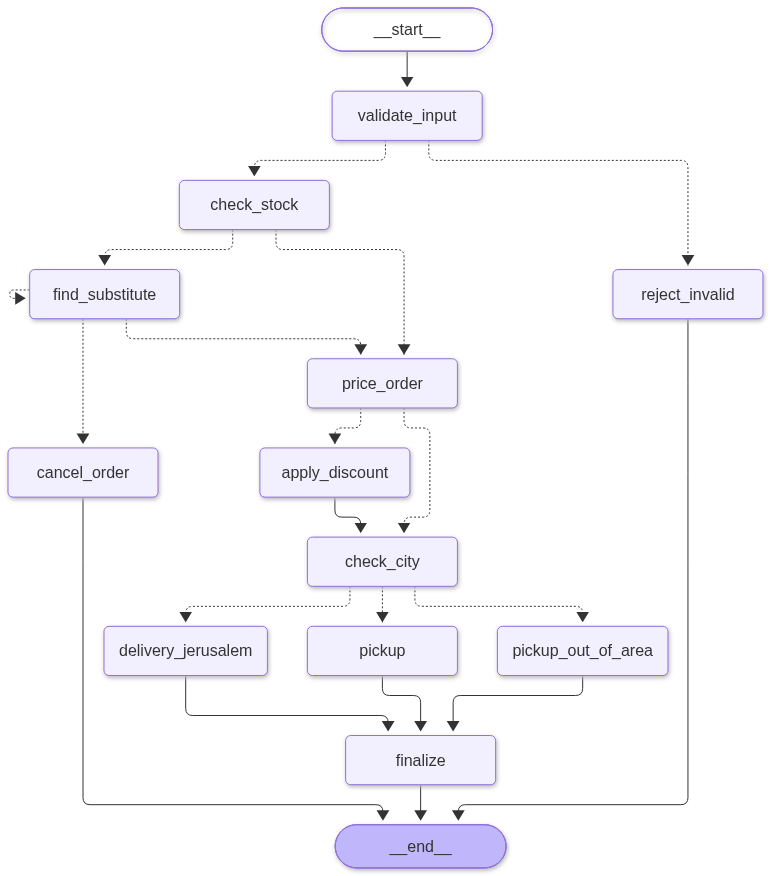

In [8]:
display(Image(graph.get_graph().draw_mermaid_png()))

## הרצה לדוגמה
התוצאה הצפויה: באבקה נגמרה, ולכן מקבלים 2 קופסאות רוגלך (60 ₪) ועוד משלוח לירושלים (20 ₪), סה״כ 80 ₪.

In [9]:
REQUIRED_KEYS = ("status", "item", "delivery", "total", "message", "steps")


def show(result):
    for key in REQUIRED_KEYS[:4]:
        print(f"{key:9}{result[key]}")
    print("message:")
    print(result["message"])
    print("steps:")
    for step in result["steps"]:
        print("  ", step)


result = graph.invoke({"item": "babka", "quantity": 2, "day": "Thursday", "city": "Jerusalem"})
show(result)

status   accepted
item     rugelach
delivery delivery
total    80
message:
היי, תודה רבה על ההזמנה!
לא נשאר לנו היום מספיק באבקה, אז הכנו לכם במקום 2 × קופסת רוגלך. מקווה שתאהבו!
ההזמנה תגיע אליכם עם שליח בירושלים (משלוח 20 ₪).
סה״כ לתשלום: 80 ₪.
באהבה, דנה
steps:
   validate_input: ok, 2 x babka on Thursday
   check_stock: 0 babka for 2, not enough
   find_substitute: offer #1 babka -> rugelach, enough
   price_order: 2 x rugelach = 60
   check_city: 'Jerusalem' -> jerusalem
   delivery_jerusalem: courier, fee 20
   finalize: accepted, total 80


## הזמנות בדיקה
15 הזמנות שעוברות בכל הקשתות בגרף. לכל הזמנה בודקים את ערכי הפלט, שכל 6 המפתחות קיימים, ושרצף ה־nodes ב־`steps` הוא הרצף הצפוי.

In [10]:
OK = ["validate_input", "check_stock"]
TO_DELIVERY = ["check_city", "delivery_jerusalem", "finalize"]
SUB = ["find_substitute"]

TESTS = [
    # (description, input, expected status, item, delivery, total, expected node path)
    ("unknown product", {"item": "pizza", "quantity": 1, "day": "Sunday", "city": ""},
     "rejected", None, "pickup", 0, ["validate_input", "reject_invalid"]),
    ("zero quantity", {"item": "challah", "quantity": 0, "day": "Sunday", "city": ""},
     "rejected", None, "pickup", 0, ["validate_input", "reject_invalid"]),
    ("croissant is discontinued", {"item": "croissant", "quantity": 2, "day": "Monday", "city": "Jerusalem"},
     "rejected", None, "pickup", 0, ["validate_input", "reject_invalid"]),
    ("invalid day", {"item": "challah", "quantity": 2, "day": "Blursday", "city": ""},
     "rejected", None, "pickup", 0, ["validate_input", "reject_invalid"]),
    ("in stock, delivery", {"item": "challah", "quantity": 3, "day": "Sunday", "city": "Jerusalem"},
     "accepted", "challah", "delivery", 74, OK + ["price_order"] + TO_DELIVERY),
    ("first substitute", {"item": "babka", "quantity": 2, "day": "Thursday", "city": "Jerusalem"},
     "accepted", "rugelach", "delivery", 80, OK + SUB + ["price_order"] + TO_DELIVERY),
    ("second substitute, delivery", {"item": "rugelach", "quantity": 5, "day": "Monday", "city": "Jerusalem"},
     "accepted", "challah", "delivery", 110, OK + SUB * 2 + ["price_order"] + TO_DELIVERY),
    ("second substitute, pickup", {"item": "babka", "quantity": 4, "day": "Monday", "city": ""},
     "accepted", "sourdough", "pickup", 100, OK + SUB * 2 + ["price_order", "check_city", "pickup", "finalize"]),
    ("cancelled after 2 offers", {"item": "babka", "quantity": 5, "day": "Tuesday", "city": "Jerusalem"},
     "rejected", None, "pickup", 0, OK + SUB * 2 + ["cancel_order"]),
    ("cancelled, no substitute", {"item": "challah", "quantity": 12, "day": "Wednesday", "city": ""},
     "rejected", None, "pickup", 0, OK + SUB + ["cancel_order"]),
    ("discount (180 - 27 + 20)", {"item": "challah", "quantity": 10, "day": "Thursday", "city": "Jerusalem"},
     "accepted", "challah", "delivery", 173, OK + ["price_order", "apply_discount"] + TO_DELIVERY),
    ("Friday, no discount", {"item": "challah", "quantity": 10, "day": "Friday", "city": "Jerusalem"},
     "accepted", "challah", "delivery", 200, OK + ["price_order"] + TO_DELIVERY),
    ("outside Jerusalem", {"item": "sourdough", "quantity": 2, "day": "Sunday", "city": "Tel Aviv"},
     "accepted", "sourdough", "pickup", 50, OK + ["price_order", "check_city", "pickup_out_of_area", "finalize"]),
    ("substitute + discount + delivery", {"item": "sourdough", "quantity": 9, "day": "Thursday", "city": "Jerusalem"},
     "accepted", "challah", "delivery", 157.7, OK + SUB + ["price_order", "apply_discount"] + TO_DELIVERY),
    ("messy input is normalized", {"item": "  Babka ", "quantity": 2, "day": "thursday", "city": "jerusalem"},
     "accepted", "rugelach", "delivery", 80, OK + SUB + ["price_order"] + TO_DELIVERY),
]

rows = []
for number, (description, order, status, item, delivery, total, path) in enumerate(TESTS, 1):
    result = graph.invoke(order)
    print(f"--- #{number} {description}: {order}")
    show(result)
    print()

    for key in REQUIRED_KEYS:
        assert key in result, f"#{number}: missing key {key}"
    assert result["status"] == status, f"#{number}: status {result['status']}"
    assert result["item"] == item, f"#{number}: item {result['item']}"
    assert result["delivery"] == delivery, f"#{number}: delivery {result['delivery']}"
    assert result["total"] == total, f"#{number}: total {result['total']}"
    nodes = [step.split(":")[0] for step in result["steps"]]
    assert nodes == path, f"#{number}: path {nodes}"

    rows.append({"#": number, "test": description, "status": result["status"],
                 "item": result["item"], "delivery": result["delivery"],
                 "total": result["total"], "path": " → ".join(nodes)})

print(f"All {len(TESTS)} tests passed.")

--- #1 unknown product: {'item': 'pizza', 'quantity': 1, 'day': 'Sunday', 'city': ''}
status   rejected
item     None
delivery pickup
total    0
message:
שלום, ותודה שפניתם אלינו!
לצערי לא הצלחנו להבין את ההזמנה שהתקבלה. אפשר לנסות למלא את הטופס שוב? נשמח לאפות בשבילכם.
באהבה, דנה
steps:
   validate_input: invalid, unknown product 'pizza'
   reject_invalid: order rejected

--- #2 zero quantity: {'item': 'challah', 'quantity': 0, 'day': 'Sunday', 'city': ''}
status   rejected
item     None
delivery pickup
total    0
message:
שלום, ותודה שפניתם אלינו!
לצערי לא הצלחנו להבין את ההזמנה שהתקבלה. אפשר לנסות למלא את הטופס שוב? נשמח לאפות בשבילכם.
באהבה, דנה
steps:
   validate_input: invalid, invalid quantity 0
   reject_invalid: order rejected

--- #3 croissant is discontinued: {'item': 'croissant', 'quantity': 2, 'day': 'Monday', 'city': 'Jerusalem'}
status   rejected
item     None
delivery pickup
total    0
message:
שלום, ותודה שפניתם אלינו!
לצערי לא הצלחנו להבין את ההזמנה שהתקבלה. אפשר לנסו

## סיכום

In [11]:
pd.set_option("display.max_colwidth", None)
pd.DataFrame(rows).set_index("#")

,test,status,item,delivery,total,path
#,,,,,,
1,unknown product,rejected,NaN,pickup,0.0,validate_input → reject_invalid
2,zero quantity,rejected,NaN,pickup,0.0,validate_input → reject_invalid
3,croissant is discontinued,rejected,NaN,pickup,0.0,validate_input → reject_invalid
4,invalid day,rejected,NaN,pickup,0.0,validate_input → reject_invalid
5,"in stock, delivery",accepted,challah,delivery,74.0,validate_input → check_stock → price_order → check_city → delivery_jerusalem → finalize
6,first substitute,accepted,rugelach,delivery,80.0,validate_input → check_stock → find_substitute → price_order → check_city → delivery_jerusalem → finalize
7,"second substitute, delivery",accepted,challah,delivery,110.0,validate_input → check_stock → find_substitute → find_substitute → price_order → check_city → delivery_jerusalem → finalize
8,"second substitute, pickup",accepted,sourdough,pickup,100.0,validate_input → check_stock → find_substitute → find_substitute → price_order → check_city → pickup → finalize
9,cancelled after 2 offers,rejected,NaN,pickup,0.0,validate_input → check_stock → find_substitute → find_substitute → cancel_order
